# Visualización de Datos - PEC 2

## Visualización 1 - Word cloud

### Descripción del conjunto de datos y objetivo

- Fichero de datos: https://www.kaggle.com/datasets/rmisra/news-category-dataset/data
- Descripción: Titulares del medio de comunicación HuffPost (https://www.huffpost.com/) desde 2012 a 2022. Hay más de 210.000 registros. Cada registro contiene una categoría a la que pertenece el titular, el propio titular, autores, enlace al artículo, pequeña descripción y fecha de publicación.
- Objetivo: Nosotros seleccionaremos aquellas cuyo campo `category` es `SPORTS` y extraemos el campo `headline` en la lista `titulares_sports`.
Nuestro objetivo es analizar qué palabras se utilizaron más durante estos años en los titulares de noticias deportivas.


### Carga del conjunto de datos

In [1]:
import json
from pathlib import Path

ruta_json = Path("News_Category_Dataset_v3.json")
with ruta_json.open(encoding="utf-8") as fichero:
    noticias = [json.loads(linea) for linea in fichero if linea.strip()]

noticias_sports = [noticia for noticia in noticias if noticia["category"] == "SPORTS"]
titulares_sports = [noticia["headline"] for noticia in noticias_sports]

print(f"Titulares de SPORTS: {len(titulares_sports)}")
titulares_sports[:5]


Titulares de SPORTS: 5077


['Maury Wills, Base-Stealing Shortstop For Dodgers, Dies At 89',
 'Las Vegas Aces Win First WNBA Title, Chelsea Gray Named MVP',
 'Boston Marathon To Make Race More Inclusive For Nonbinary Runners',
 'Anthony Varvaro, MLB Pitcher Turned Transit Cop, Dies In Crash On Way To 9/11 Ceremony',
 'Carlos Alcaraz Wins U.S. Open For 1st Slam Title, Top Ranking']

### Limpieza y adecuación del conjunto de datos

Convertimos los titulares a minúsculas y extraemos las palabras sin puntuación ni números. Reunimos todas las palabras en una única lista, excluyendo las incluidas en `ENGLISH_STOP_WORDS` y conservando las repeticiones.

In [2]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

palabras_sports = [
    palabra
    for titular in titulares_sports
    for palabra in re.findall(r"\b[^\W\d_]+\b", titular.lower())
    if palabra not in ENGLISH_STOP_WORDS and len(palabra) > 2
]

print(f"Palabras sin stop words: {len(palabras_sports)}")
palabras_sports[:5]

Palabras sin stop words: 36425


['maury', 'wills', 'base', 'stealing', 'shortstop']

### Generación de la visualización tipo Word Cloud

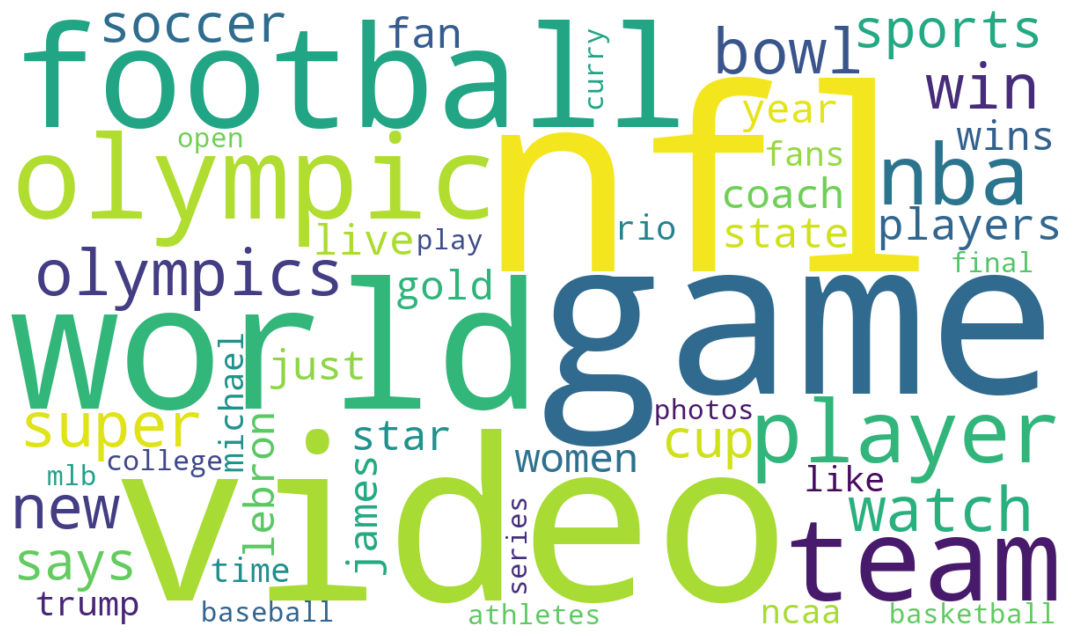

In [3]:
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

frecuencias = Counter(palabras_sports)
top_50 = dict(frecuencias.most_common(50))

wordcloud = WordCloud(
    width=1200,
    height=700,
    background_color="white"
).generate_from_frequencies(top_50)

plt.figure(figsize=(14, 8))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()